# 04 — Final Mouth Extraction (Full Video, 2 Speakers)

Notebook นี้ใช้ผล Final Re-ID โดยตรง:

`dataset/reid/video001/final_2speaker/final_2speaker_detection.csv`

เพื่อสร้าง mouth crops 96×96 ของ Speaker 0 และ Speaker 1 ตลอดทั้งวิดีโอ โดย **ไม่รัน YOLO ใหม่**

คุณสมบัติ:
- ใช้ bbox จาก Final 2-Speaker Detection
- ใช้ `face_alignment` 68 landmarks บน CUDA
- align ใบหน้าแล้ว crop ปากจาก landmark 48–67
- เก็บแยก `speaker_000/` และ `speaker_001/`
- ข้าม row ที่ `REVIEW`
- มี progress bar + ETA
- checkpoint / resume ได้
- append metadata เป็นช่วง ๆ
- ประหยัดพื้นที่: ไม่เก็บ aligned face และเซฟ JPG quality 85

## Cell 1 — Environment

In [1]:
import sys
import torch

print("=" * 70)
print("ENVIRONMENT")
print("=" * 70)
print("Python :", sys.executable)
print("Version:", sys.version.split()[0])
print("Torch  :", torch.__version__)
print("CUDA   :", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("กรุณาใช้ Kernel Python 3.12 ที่มี PyTorch CUDA")

print("GPU    :", torch.cuda.get_device_name(0))

ENVIRONMENT
Python : c:\Users\ASUS FA507NUR\AppData\Local\Programs\Python\Python312\python.exe
Version: 3.12.9
Torch  : 2.6.0+cu124
CUDA   : True
GPU    : NVIDIA GeForce RTX 4050 Laptop GPU


## Cell 2 — Path / Config

In [2]:
from pathlib import Path

PROJECT_ROOT = Path(r"D:\Face_detection")
VIDEO_ID = "video001"

VIDEO_PATH = (
    PROJECT_ROOT
    / "dataset"
    / "raw_videos"
    / f"{VIDEO_ID}.webm"
)

FINAL_DETECTION_CSV = (
    PROJECT_ROOT
    / "dataset"
    / "reid"
    / VIDEO_ID
    / "final_2speaker"
    / "final_2speaker_detection.csv"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "dataset"
    / "mouth_crops_final"
    / VIDEO_ID
)

PREVIEW_DIR = OUTPUT_ROOT / "preview"
CHECKPOINT_PATH = OUTPUT_ROOT / "checkpoint.json"
METADATA_CSV = OUTPUT_ROOT / "mouth_metadata.csv"

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
PREVIEW_DIR.mkdir(parents=True, exist_ok=True)

print("VIDEO_PATH         :", VIDEO_PATH)
print("FINAL_DETECTION_CSV:", FINAL_DETECTION_CSV)
print("OUTPUT_ROOT        :", OUTPUT_ROOT)

if not VIDEO_PATH.exists():
    raise FileNotFoundError(VIDEO_PATH)

if not FINAL_DETECTION_CSV.exists():
    raise FileNotFoundError(FINAL_DETECTION_CSV)

VIDEO_PATH         : D:\Face_detection\dataset\raw_videos\video001.webm
FINAL_DETECTION_CSV: D:\Face_detection\dataset\reid\video001\final_2speaker\final_2speaker_detection.csv
OUTPUT_ROOT        : D:\Face_detection\dataset\mouth_crops_final\video001


## Cell 3 — Load Final 2-Speaker Detection

In [3]:
import pandas as pd
import numpy as np

det_df = pd.read_csv(FINAL_DETECTION_CSV)

required = {
    "frame_index",
    "track_id",
    "speaker_id",
    "status",
    "x1", "y1", "x2", "y2",
    "det_score",
}

missing = required - set(det_df.columns)

if missing:
    raise ValueError(f"CSV ขาด columns: {missing}")

# ใช้เฉพาะ AUTO + speaker ที่ assign แล้ว
det_df = det_df[
    (det_df["status"] == "AUTO")
    &
    (det_df["speaker_id"].notna())
].copy()

det_df["frame_index"] = det_df["frame_index"].astype(int)
det_df["track_id"] = det_df["track_id"].astype(int)
det_df["speaker_id"] = det_df["speaker_id"].astype(int)

# ถ้าเฟรมเดียว speaker เดียวมีหลาย detection
# เก็บเฉพาะ confidence สูงสุด
det_df = (
    det_df.sort_values("det_score", ascending=False)
    .drop_duplicates(
        subset=["frame_index", "speaker_id"],
        keep="first"
    )
    .sort_values(["frame_index", "speaker_id"])
    .reset_index(drop=True)
)

print("AUTO detection rows:", len(det_df))
print("Speaker IDs:", sorted(det_df["speaker_id"].unique().tolist()))
print("Min frame:", det_df["frame_index"].min())
print("Max frame:", det_df["frame_index"].max())

display(
    det_df.groupby("speaker_id").agg(
        detections=("frame_index", "count"),
        first_frame=("frame_index", "min"),
        last_frame=("frame_index", "max"),
        mean_conf=("det_score", "mean"),
    )
)

AUTO detection rows: 256152
Speaker IDs: [0, 1]
Min frame: 0
Max frame: 178333


,detections,first_frame,last_frame,mean_conf
speaker_id,,,,
0,118277,0,178333,0.826957
1,137875,0,178333,0.815844


## Cell 4 — Video Info

In [4]:
import cv2

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError(f"เปิดวิดีโอไม่ได้: {VIDEO_PATH}")

FPS = float(cap.get(cv2.CAP_PROP_FPS))
TOTAL_FRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
WIDTH = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
HEIGHT = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

cap.release()

print("FPS         :", FPS)
print("Total frames:", TOTAL_FRAMES)
print("Resolution  :", f"{WIDTH}x{HEIGHT}")
print("Duration    :", round(TOTAL_FRAMES / FPS / 60, 2), "minutes")

FPS         : 29.97002997002997
Total frames: 178335
Resolution  : 1920x1080
Duration    : 99.17 minutes


## Cell 5 — Load Face Alignment

In [5]:
import face_alignment

fa = face_alignment.FaceAlignment(
    face_alignment.LandmarksType.TWO_D,
    device="cuda",
    flip_input=False,
    compile=False,
)

print("Face Alignment ready")

Face Alignment ready


## Cell 6 — Alignment + Mouth Crop Functions

In [6]:
import cv2
import numpy as np

ALIGNED_SIZE = 256
MOUTH_OUTPUT_SIZE = 96
MOUTH_CROP_SIZE = 104

DST_LEFT_EYE  = np.array([76.0, 92.0], dtype=np.float32)
DST_RIGHT_EYE = np.array([180.0, 92.0], dtype=np.float32)
DST_MOUTH     = np.array([128.0, 174.0], dtype=np.float32)


def transform_points(points, matrix):
    points = np.asarray(points, dtype=np.float32)
    ones = np.ones((len(points), 1), dtype=np.float32)
    homo = np.concatenate([points, ones], axis=1)
    return homo @ matrix.T


def align_face(frame, landmarks):
    landmarks = np.asarray(landmarks, dtype=np.float32)

    left_eye_center = landmarks[36:42].mean(axis=0)
    right_eye_center = landmarks[42:48].mean(axis=0)
    mouth_center = landmarks[48:68].mean(axis=0)

    src = np.float32([
        left_eye_center,
        right_eye_center,
        mouth_center,
    ])

    dst = np.float32([
        DST_LEFT_EYE,
        DST_RIGHT_EYE,
        DST_MOUTH,
    ])

    matrix = cv2.getAffineTransform(src, dst)

    aligned = cv2.warpAffine(
        frame,
        matrix,
        (ALIGNED_SIZE, ALIGNED_SIZE),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT_101,
    )

    aligned_landmarks = transform_points(
        landmarks,
        matrix,
    )

    return aligned, aligned_landmarks


def crop_mouth(aligned_face, aligned_landmarks):
    mouth_points = aligned_landmarks[48:68]
    mouth_center = mouth_points.mean(axis=0)

    cx = int(round(mouth_center[0]))
    cy = int(round(mouth_center[1] + 3))

    half = MOUTH_CROP_SIZE // 2

    x1 = cx - half
    y1 = cy - half
    x2 = x1 + MOUTH_CROP_SIZE
    y2 = y1 + MOUTH_CROP_SIZE

    pad_left = max(0, -x1)
    pad_top = max(0, -y1)
    pad_right = max(0, x2 - ALIGNED_SIZE)
    pad_bottom = max(0, y2 - ALIGNED_SIZE)

    if any([pad_left, pad_top, pad_right, pad_bottom]):
        padded = cv2.copyMakeBorder(
            aligned_face,
            pad_top, pad_bottom,
            pad_left, pad_right,
            cv2.BORDER_REFLECT_101,
        )

        x1 += pad_left
        x2 += pad_left
        y1 += pad_top
        y2 += pad_top
    else:
        padded = aligned_face

    mouth = padded[y1:y2, x1:x2]

    if mouth.size == 0:
        return None

    mouth_96 = cv2.resize(
        mouth,
        (MOUTH_OUTPUT_SIZE, MOUTH_OUTPUT_SIZE),
        interpolation=cv2.INTER_AREA,
    )

    return mouth_96


def blur_score(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    return float(
        cv2.Laplacian(
            gray,
            cv2.CV_64F,
        ).var()
    )


def brightness_score(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return float(gray.mean())


print("Functions ready")

Functions ready


## Cell 7 — QA 1 Frame ก่อน Full Run

In [7]:
test_frame = int(det_df["frame_index"].min())

test_rows = det_df[
    det_df["frame_index"] == test_frame
].copy()

cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_FRAMES, test_frame)
ret, frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError("อ่าน test frame ไม่ได้")

boxes = test_rows[
    ["x1", "y1", "x2", "y2"]
].to_numpy(dtype=np.float32)

landmarks_list = fa.get_landmarks_from_image(
    frame,
    detected_faces=boxes.tolist(),
)

print("Frame:", test_frame)
print("Detections:", len(test_rows))
print(
    "Landmark sets:",
    0 if landmarks_list is None else len(landmarks_list)
)

Frame: 0
Detections: 2
Landmark sets: 2


## Cell 8 — Full Run Config

In [8]:
# ประหยัดพื้นที่
JPEG_QUALITY = 85
SAVE_PREVIEW_EVERY = 2000

# quality
MIN_BLUR_SCORE = 15.0
MIN_DET_SCORE = 0.30

# checkpoint
CHECKPOINT_EVERY_TARGET_FRAMES = 500
METADATA_FLUSH_EVERY = 2000

print("JPEG_QUALITY:", JPEG_QUALITY)
print("SAVE_PREVIEW_EVERY:", SAVE_PREVIEW_EVERY)
print("CHECKPOINT_EVERY_TARGET_FRAMES:", CHECKPOINT_EVERY_TARGET_FRAMES)

JPEG_QUALITY: 85
SAVE_PREVIEW_EVERY: 2000
CHECKPOINT_EVERY_TARGET_FRAMES: 500


## Cell 9 — Resume / Checkpoint

ถ้ารอบก่อนหยุดกลางทาง Notebook จะอ่าน `checkpoint.json` แล้วเริ่มต่อจากเฟรมถัดไป

ถ้าต้องการเริ่มใหม่จริง ๆ ให้ลบ:
- `checkpoint.json`
- `mouth_metadata.csv`
- โฟลเดอร์ `speaker_000/`, `speaker_001/`

In [9]:
import json

resume_from_frame = 0

if CHECKPOINT_PATH.exists():
    with open(
        CHECKPOINT_PATH,
        "r",
        encoding="utf-8"
    ) as f:
        checkpoint = json.load(f)

    resume_from_frame = int(
        checkpoint.get(
            "last_completed_frame",
            -1
        )
    ) + 1

print("Resume from frame:", resume_from_frame)

Resume from frame: 0


## Cell 10 — Prepare Frame Groups

In [10]:
frame_groups = {
    int(frame_idx): group.copy()
    for frame_idx, group in det_df.groupby("frame_index")
    if int(frame_idx) >= resume_from_frame
}

target_frames = sorted(frame_groups.keys())

print("Target frames remaining:", len(target_frames))

if target_frames:
    print("First target frame:", target_frames[0])
    print("Last target frame :", target_frames[-1])
else:
    print("ไม่มี target frame เหลือ — อาจประมวลผลเสร็จแล้ว")

Target frames remaining: 178069
First target frame: 0
Last target frame : 178333


## Cell 11 — Full Mouth Extraction (Progress + ETA + Resume)

In [11]:
import time
from tqdm.auto import tqdm

# output folders
for speaker_id in sorted(det_df["speaker_id"].unique()):
    (
        OUTPUT_ROOT
        / f"speaker_{int(speaker_id):03d}"
    ).mkdir(
        parents=True,
        exist_ok=True
    )

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError(f"เปิดวิดีโอไม่ได้: {VIDEO_PATH}")

if target_frames:
    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        target_frames[0]
    )

current_video_frame = (
    target_frames[0]
    if target_frames
    else 0
)

metadata_buffer = []

processed_target_frames = 0
saved_mouths = 0
rejected_mouths = 0

start_time_wall = time.time()

target_frame_set = set(target_frames)
last_target_frame = (
    target_frames[-1]
    if target_frames
    else -1
)

pbar = tqdm(
    total=len(target_frames),
    desc="mouth extraction",
    unit="target-frame"
)

while (
    target_frames
    and current_video_frame <= last_target_frame
):

    ret, frame = cap.read()

    if not ret:
        print("วิดีโอจบก่อน target frame")
        break

    if current_video_frame not in target_frame_set:
        current_video_frame += 1
        continue

    frame_rows = (
        frame_groups[current_video_frame]
        .sort_values("speaker_id")
        .copy()
    )

    frame_rows = frame_rows[
        frame_rows["det_score"] >= MIN_DET_SCORE
    ]

    if len(frame_rows) == 0:
        processed_target_frames += 1
        pbar.update(1)
        current_video_frame += 1
        continue

    boxes = frame_rows[
        ["x1", "y1", "x2", "y2"]
    ].to_numpy(dtype=np.float32)

    try:
        landmark_sets = fa.get_landmarks_from_image(
            frame,
            detected_faces=boxes.tolist(),
        )
    except Exception as e:
        landmark_sets = None

    preview_frame = frame.copy()

    if landmark_sets is not None:

        usable_count = min(
            len(frame_rows),
            len(landmark_sets)
        )

        for pos in range(usable_count):

            row = frame_rows.iloc[pos]
            landmarks = landmark_sets[pos]

            speaker_id = int(
                row["speaker_id"]
            )

            try:
                aligned, aligned_landmarks = align_face(
                    frame,
                    landmarks
                )

                mouth = crop_mouth(
                    aligned,
                    aligned_landmarks
                )

                if mouth is None:
                    raise RuntimeError("empty mouth")

                blur = blur_score(mouth)
                brightness = brightness_score(mouth)

                accepted = (
                    blur >= MIN_BLUR_SCORE
                )

                mouth_rel = ""

                if accepted:

                    speaker_dir = (
                        OUTPUT_ROOT
                        / f"speaker_{speaker_id:03d}"
                    )

                    mouth_path = (
                        speaker_dir
                        / f"frame_{current_video_frame:08d}.jpg"
                    )

                    cv2.imwrite(
                        str(mouth_path),
                        mouth,
                        [
                            cv2.IMWRITE_JPEG_QUALITY,
                            JPEG_QUALITY,
                        ]
                    )

                    mouth_rel = str(
                        mouth_path.relative_to(
                            PROJECT_ROOT
                        )
                    )

                    saved_mouths += 1

                else:
                    rejected_mouths += 1

                metadata_buffer.append({
                    "video_id": VIDEO_ID,
                    "frame_index": int(current_video_frame),
                    "timestamp_seconds": round(
                        current_video_frame / FPS,
                        6
                    ),
                    "speaker_id": speaker_id,
                    "track_id": int(row["track_id"]),
                    "det_score": round(
                        float(row["det_score"]),
                        6
                    ),
                    "mouth_file": mouth_rel,
                    "blur_score": round(
                        blur,
                        3
                    ),
                    "brightness": round(
                        brightness,
                        3
                    ),
                    "accepted": bool(accepted),
                })

                # QA preview
                x1, y1, x2, y2 = map(
                    int,
                    [
                        row["x1"],
                        row["y1"],
                        row["x2"],
                        row["y2"],
                    ]
                )

                cv2.rectangle(
                    preview_frame,
                    (x1, y1),
                    (x2, y2),
                    (0, 255, 0),
                    2,
                )

                cv2.putText(
                    preview_frame,
                    f"S{speaker_id}",
                    (x1, max(25, y1 - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    (0, 255, 0),
                    2,
                    cv2.LINE_AA,
                )

                for x, y in np.asarray(
                    landmarks[48:68]
                ).astype(int):

                    cv2.circle(
                        preview_frame,
                        (x, y),
                        2,
                        (0, 0, 255),
                        -1,
                    )

            except Exception:
                rejected_mouths += 1

    # preview ห่าง ๆ
    if (
        SAVE_PREVIEW_EVERY > 0
        and
        processed_target_frames
        % SAVE_PREVIEW_EVERY
        == 0
    ):

        preview_path = (
            PREVIEW_DIR
            / f"frame_{current_video_frame:08d}.jpg"
        )

        cv2.imwrite(
            str(preview_path),
            preview_frame,
            [cv2.IMWRITE_JPEG_QUALITY, 80]
        )

    processed_target_frames += 1
    pbar.update(1)

    # flush metadata เป็นระยะ
    if (
        len(metadata_buffer)
        >= METADATA_FLUSH_EVERY
    ):

        chunk_df = pd.DataFrame(
            metadata_buffer
        )

        write_header = (
            not METADATA_CSV.exists()
            or METADATA_CSV.stat().st_size == 0
        )

        chunk_df.to_csv(
            METADATA_CSV,
            mode="a",
            header=write_header,
            index=False,
            encoding="utf-8-sig",
        )

        metadata_buffer = []

    # checkpoint
    if (
        processed_target_frames
        % CHECKPOINT_EVERY_TARGET_FRAMES
        == 0
    ):

        with open(
            CHECKPOINT_PATH,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                {
                    "last_completed_frame":
                        int(current_video_frame),
                    "processed_target_frames":
                        int(processed_target_frames),
                    "saved_mouths":
                        int(saved_mouths),
                    "rejected_mouths":
                        int(rejected_mouths),
                },
                f,
                ensure_ascii=False,
                indent=2,
            )

    current_video_frame += 1


cap.release()
pbar.close()


# flush ที่เหลือ
if metadata_buffer:

    chunk_df = pd.DataFrame(
        metadata_buffer
    )

    write_header = (
        not METADATA_CSV.exists()
        or METADATA_CSV.stat().st_size == 0
    )

    chunk_df.to_csv(
        METADATA_CSV,
        mode="a",
        header=write_header,
        index=False,
        encoding="utf-8-sig",
    )


# final checkpoint
if target_frames:

    with open(
        CHECKPOINT_PATH,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            {
                "last_completed_frame":
                    int(last_target_frame),
                "processed_target_frames":
                    int(processed_target_frames),
                "saved_mouths":
                    int(saved_mouths),
                "rejected_mouths":
                    int(rejected_mouths),
                "completed":
                    True,
            },
            f,
            ensure_ascii=False,
            indent=2,
        )


elapsed = time.time() - start_time_wall

print("\n" + "=" * 70)
print("DONE")
print("=" * 70)
print("Processed target frames:", processed_target_frames)
print("Saved mouths           :", saved_mouths)
print("Rejected               :", rejected_mouths)
print("Elapsed minutes        :", round(elapsed / 60, 2))
print("Metadata               :", METADATA_CSV)
print("Output                 :", OUTPUT_ROOT)

c:\Users\ASUS FA507NUR\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
mouth extraction: 100%|██████████| 178069/178069 [7:01:00<00:00,  7.05target-frame/s]     


DONE
Processed target frames: 178069
Saved mouths           : 253684
Rejected               : 2468
Elapsed minutes        : 421.02
Metadata               : D:\Face_detection\dataset\mouth_crops_final\video001\mouth_metadata.csv
Output                 : D:\Face_detection\dataset\mouth_crops_final\video001


## Cell 12 — Final Metadata QA

In [12]:
mouth_meta_df = pd.read_csv(
    METADATA_CSV
)

if mouth_meta_df["accepted"].dtype == object:
    mouth_meta_df["accepted"] = (
        mouth_meta_df["accepted"]
        .astype(str)
        .str.lower()
        .isin(["true", "1", "yes"])
    )

summary = (
    mouth_meta_df
    .groupby("speaker_id")
    .agg(
        total=("frame_index", "count"),
        accepted=("accepted", "sum"),
        first_frame=("frame_index", "min"),
        last_frame=("frame_index", "max"),
        mean_blur=("blur_score", "mean"),
        mean_brightness=("brightness", "mean"),
        mean_det_score=("det_score", "mean"),
    )
)

summary["accept_rate"] = (
    summary["accepted"]
    / summary["total"]
)

display(summary)

,total,accepted,first_frame,last_frame,mean_blur,mean_brightness,mean_det_score,accept_rate
speaker_id,,,,,,,,
0,118277,117267,0,178333,43.805536,134.261506,0.826957,0.991461
1,137875,136417,0,178333,54.523161,143.472040,0.815844,0.989425


## Cell 13 — Coverage เทียบ Transcript

In [13]:
TRANSCRIPT_CSV = (
    PROJECT_ROOT
    / "dataset"
    / "transcripts"
    / VIDEO_ID
    / "transcript_with_frames.csv"
)

transcript_df = pd.read_csv(
    TRANSCRIPT_CSV
)

max_mouth_frame = int(
    mouth_meta_df["frame_index"].max()
)

max_transcript_frame = int(
    transcript_df["end_frame"].max()
)

coverage = (
    max_mouth_frame
    / max_transcript_frame
    if max_transcript_frame > 0
    else 0
)

print("Max mouth frame     :", max_mouth_frame)
print("Max transcript frame:", max_transcript_frame)
print("Approx coverage     :", f"{coverage:.2%}")

Max mouth frame     : 178333
Max transcript frame: 178258
Approx coverage     : 100.04%


## Cell 14 — Preview Mouth Crops


Speaker 0: 117267 mouth images


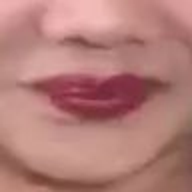

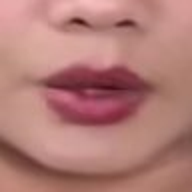

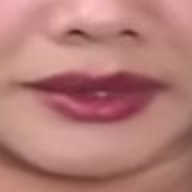

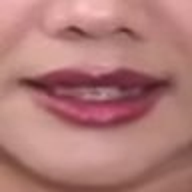

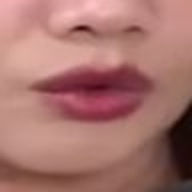

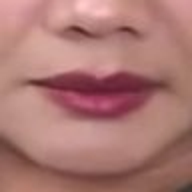

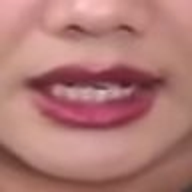

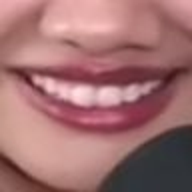


Speaker 1: 136417 mouth images


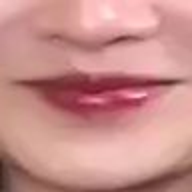

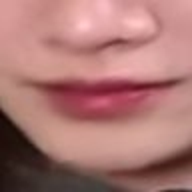

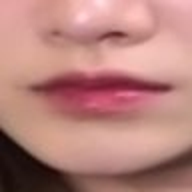

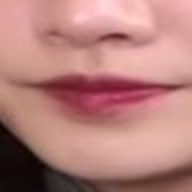

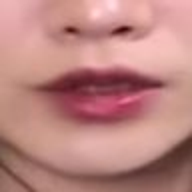

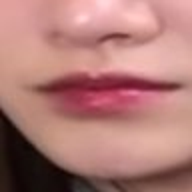

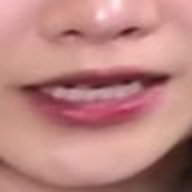

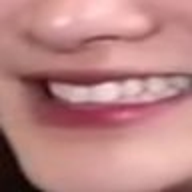

In [14]:
from PIL import Image
from IPython.display import display

for speaker_id in sorted(
    mouth_meta_df["speaker_id"]
    .dropna()
    .astype(int)
    .unique()
):

    speaker_dir = (
        OUTPUT_ROOT
        / f"speaker_{speaker_id:03d}"
    )

    files = sorted(
        speaker_dir.glob("frame_*.jpg")
    )

    print(
        f"\nSpeaker {speaker_id}: "
        f"{len(files)} mouth images"
    )

    if not files:
        continue

    sample_indices = np.linspace(
        0,
        len(files) - 1,
        min(8, len(files))
    ).astype(int)

    for idx in sample_indices:
        display(
            Image.open(
                files[idx]
            ).resize(
                (192, 192)
            )
        )

# ขั้นต่อไป

เมื่อ:
- Mouth extraction ครบทั้งคลิป
- coverage ใกล้ 100%
- mouth crop ของ Speaker 0/1 ถูกต้อง

ให้ไปขั้น **Speaker ↔ Transcript Alignment** โดยใช้:
- `mouth_metadata.csv` ชุด final
- `transcript_with_frames.csv`

จากนั้นจึงสร้าง labeled lip clips สำหรับ train